In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scrublet as scr
import session_info

In [2]:
import session_info
session_info.show()

/home/Data_Drive_8TB/ahwodn/.conda/envs/ahwodn_2/lib/python3.10/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
/home/Data_Drive_8TB/ahwodn/.conda/envs/ahwodn_2/lib/python3.10/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300, facecolor='white', color_map = 'RdPu',)

# annotation

In [4]:
adata=sc.read_h5ad(
    '/path/to/h5ad_subcluster/07_myeloid_harmony_bbk_hvg4000.h5ad')

In [5]:
res=1.4 
sc.tl.leiden(adata,resolution=res,
             key_added=f'res_{res}',
             flavor='igraph',
             n_iterations=2)

running Leiden clustering
    finished: found 27 clusters and added
    'res_1.4', the cluster labels (adata.obs, categorical) (0:00:37)


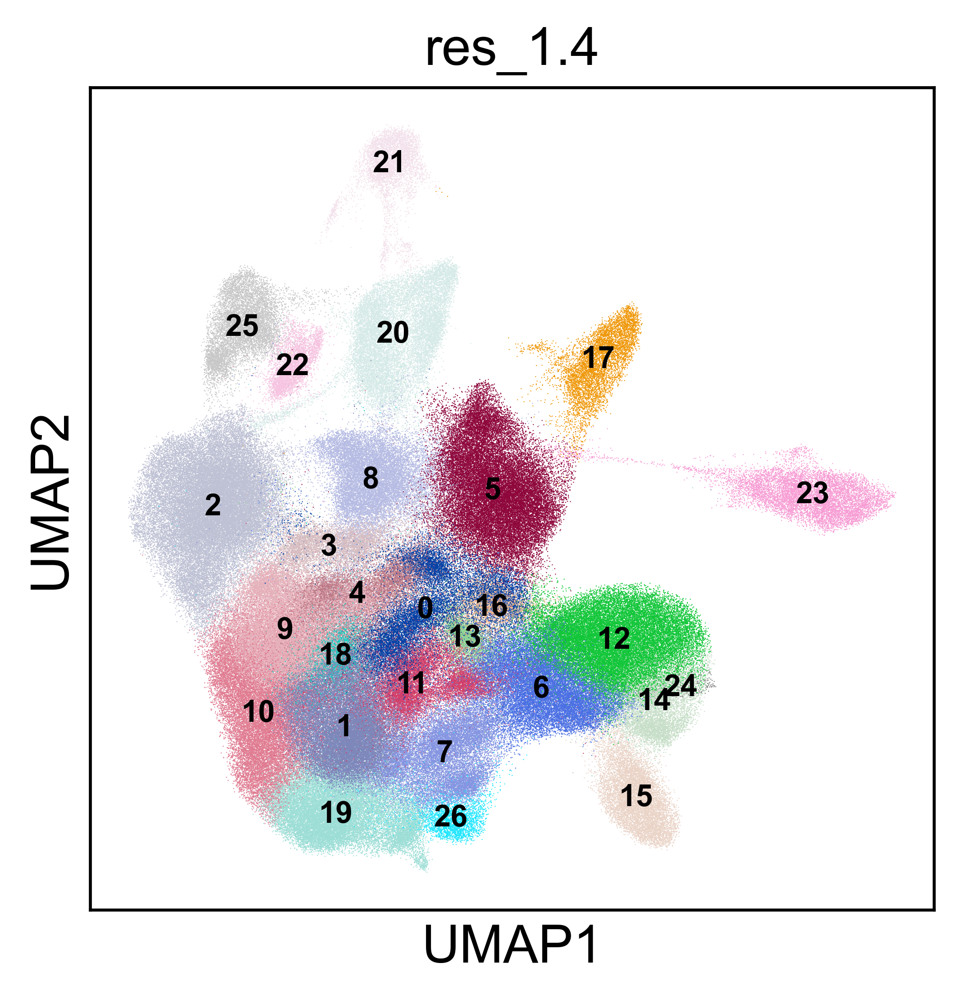

In [6]:
sc.pl.umap(adata,color=['res_1.4'],legend_loc='on data',legend_fontsize='xx-small')

In [7]:
# 클러스터 → annotation 매핑
cluster_to_anno = {
    # Macro
    '1': 'Macro', '3': 'Macro', '4': 'Macro', '18': 'Macro', '2': 'Macro',
    '9': 'FOLR2+ Macro', '10': 'FOLR2+ Macro',
    '0': 'CXCL3+ Macro',
    '19': 'SPP1+ Macro',
    '7': 'SPP1+ CXCL3+ Macro',
    '20': 'SPP1+ cycMacro',
    '26': 'SPP1+ MT1+ Macro',
    '11': 'TNFSF10+ Macro', 
    '13': 'HSPA6+ Macro',
    # Mono
    '6': 'CD14+ Mono', '12': 'CD14+ Mono', '16': 'CD14+ Mono',
    '24': 'CD14+ Mono', '14': 'CD14+ Mono',
    '15': 'CD16+ Mono',
    # DC
    '5': 'CD1C+ cDC',
    '17': 'LAMP3+ cDC',
    '21': 'CLEC9A+ cDC',
    '23': 'LILRA4+ pDC',
    # Doublet
    '8': 'Doublet_T',
    '22': 'Doublet_Fibro',
    '25': 'Doublet_Epi',
}

annot_ordering = ['Macro',
                  'FOLR2+ Macro',
                  'CXCL3+ Macro',
                  'SPP1+ Macro',       
                  'SPP1+ cycMacro',
                  'SPP1+ CXCL3+ Macro',
                  'SPP1+ MT1+ Macro',
                  'TNFSF10+ Macro',
                  'HSPA6+ Macro',
                  'CD14+ Mono',
                  'CD16+ Mono',
                  'CD1C+ cDC',
                  'LAMP3+ cDC',
                  'CLEC9A+ cDC',
                  'LILRA4+ pDC',
                  'Doublet_T',
                  'Doublet_Fibro',
                  'Doublet_Epi']

adata.obs['res_1.4_str_high_anno'] = adata.obs['res_1.4'].astype(str).map(cluster_to_anno)
adata.obs['res_1.4_str_high_anno_order'] = pd.Categorical(
    adata.obs['res_1.4_str_high_anno'], categories=annot_ordering, ordered=True
)

sc.tl.rank_genes_groups(adata, 'res_1.4_str_high_anno_order', method='wilcoxon')

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:18:13)


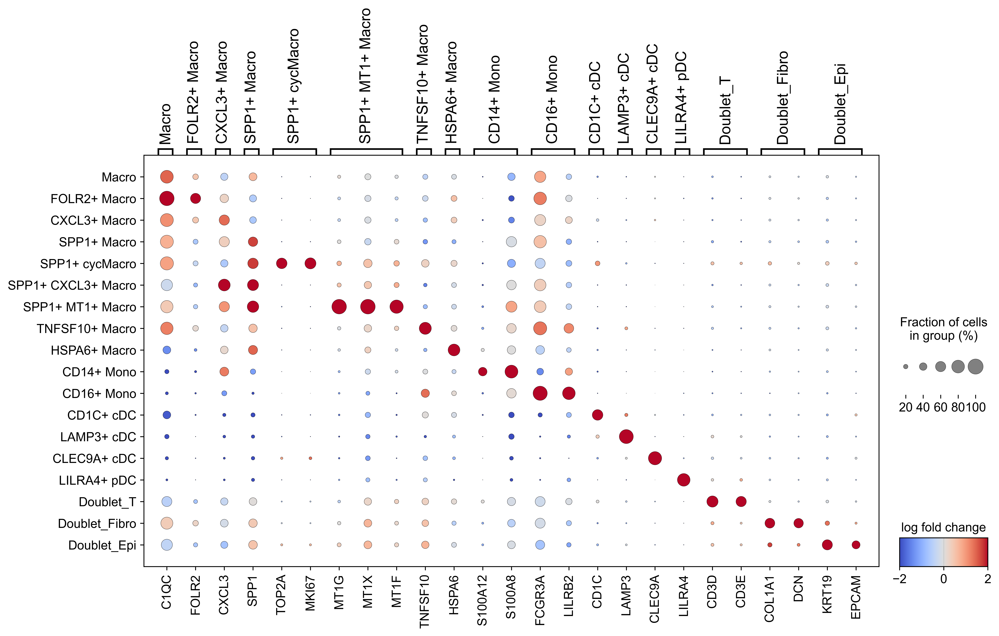

In [8]:
markers={
        'Macro':['C1QC'],
        'FOLR2+ Macro':['FOLR2'],
        'CXCL3+ Macro':['CXCL3'],
        'SPP1+ Macro':['SPP1'],
        'SPP1+ cycMacro':['TOP2A','MKI67'],
        'SPP1+ MT1+ Macro':['MT1G','MT1X','MT1F'],
        'TNFSF10+ Macro':['TNFSF10'],
        'HSPA6+ Macro':['HSPA6'],
        'CD14+ Mono':['S100A12','S100A8'],
        'CD16+ Mono':['FCGR3A','LILRB2'],
        'CD1C+ cDC':['CD1C'],
        'LAMP3+ cDC':['LAMP3'],
        'CLEC9A+ cDC':['CLEC9A'],
        'LILRA4+ pDC':['LILRA4'],
        'Doublet_T':['CD3D','CD3E'],
        'Doublet_Fibro':['COL1A1','DCN'],
        'Doublet_Epi':['KRT19','EPCAM']}

sc.pl.rank_genes_groups_dotplot(adata, figsize=(14,7),
                                groupby='res_1.4_str_high_anno_order',
                                values_to_plot='logfoldchanges',
                                vmin=-2,
                                vmax=2,
                                dendrogram=False,
                                var_names=markers,
                                color_map ='coolwarm',
                               )

In [9]:
adata.obs['sub_anno']=adata.obs['res_1.4_str_high_anno'].copy()

In [10]:
adata=adata[~adata.obs['sub_anno'].isin(['Doublet_T','Doublet_Epi','Doublet_Fibro'])]

In [11]:
del adata.obs['res_1.4_str_high_anno_order']
del adata.obs['res_1.4_str_high_anno']
del adata.obs['res_1.4']
adata.write_h5ad('/path/to/h5ad_annotated/_sc_Myeloid.h5ad')

In [12]:
adata=sc.read_h5ad('/path/to/h5ad_annotated/_sc_Myeloid.h5ad')

In [13]:
markers={
        'Macro':['C1QC'],
        'FOLR2+ Macro':['FOLR2'],
        'CXCL3+ Macro':['CXCL3','CXCL2'],
        'SPP1+ Macro':['SPP1'],
        'SPP1+ cycMacro':['TOP2A','MKI67'],
        'SPP1+ MT1+ Macro':['MT1G','MT1X','MT1F'],
        'TNFSF10+ Macro':['TNFSF10'],
        'HSPA6+ Macro':['HSPA6'],
        'CD14+ Mono':['S100A12','S100A8'],
        'CD16+ Mono':['FCGR3A','LILRB2'],
        'CD1C+ cDC':['CD1C'],
        'LAMP3+ cDC':['LAMP3'],
        'CLEC9A+ cDC':['CLEC9A'],
        'LILRA4+ pDC':['LILRA4'],}

annot_ordering = ['Macro',
                  'FOLR2+ Macro',
                  'CXCL3+ Macro',
                  'SPP1+ Macro',
                  'SPP1+ CXCL3+ Macro',
                  'SPP1+ cycMacro',
                  'SPP1+ MT1+ Macro',
                  'TNFSF10+ Macro',
                  'HSPA6+ Macro',
                  'CD14+ Mono',
                  'CD16+ Mono',
                  'CD1C+ cDC',
                  'LAMP3+ cDC',
                  'CLEC9A+ cDC',
                  'LILRA4+ pDC',
                 ]

adata.obs['sub_anno'] = pd.Categorical(
adata.obs['sub_anno'], categories=annot_ordering, ordered=True)


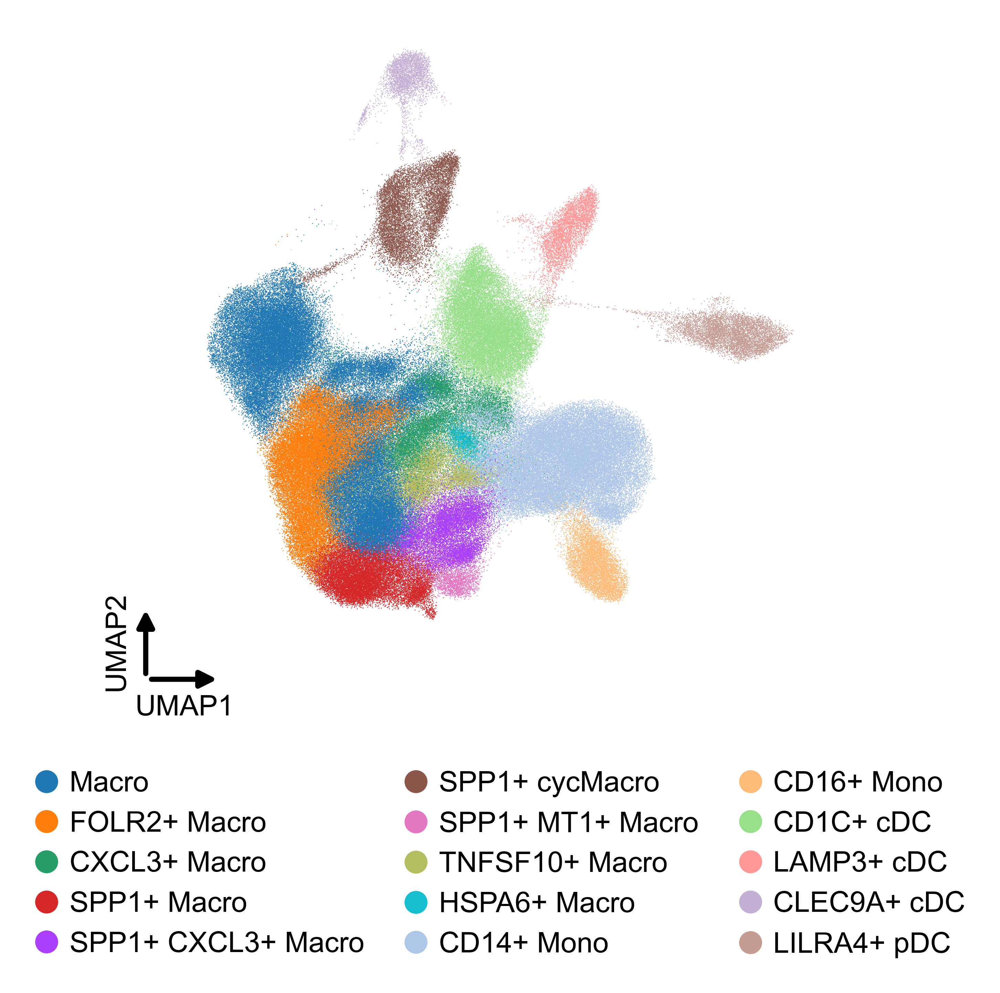

In [14]:
from plotting import umap_with_arrow_axes

umap_with_arrow_axes(adata)

In [15]:
sc.tl.rank_genes_groups(adata,groupby='sub_anno',method='wilcoxon')

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:29:58)


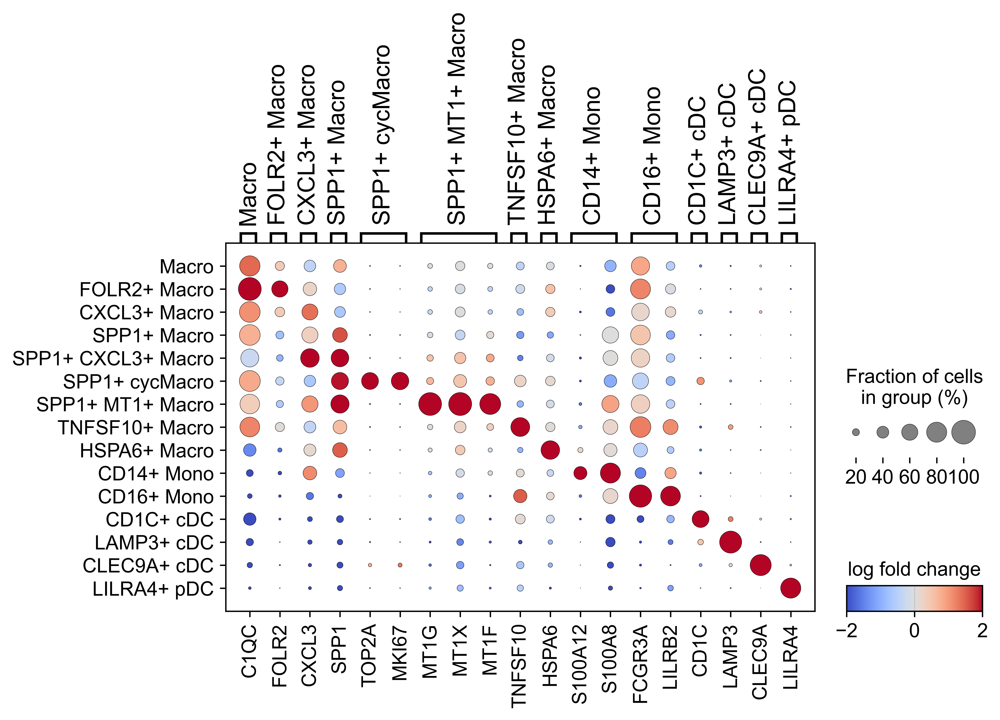

In [16]:
sc.pl.rank_genes_groups_dotplot(adata, figsize=(8,4),
                                groupby='sub_anno',
                                values_to_plot='logfoldchanges',
                                vmin=-2,
                                vmax=2,
                                dendrogram=False,
                                var_names=markers,
                                color_map ='coolwarm'
                               )

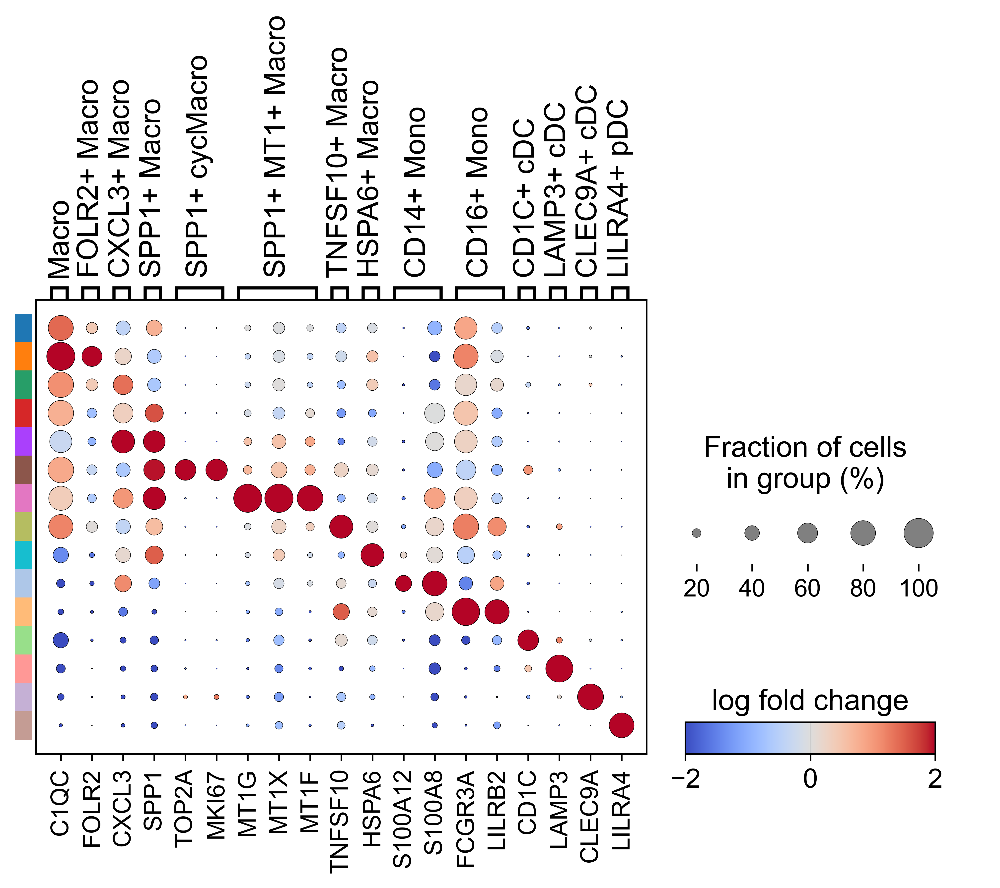

In [17]:
import matplotlib.colors as mcolors


cats = list(adata.obs["sub_anno"].cat.categories)

dp = sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="sub_anno",
    categories_order=cats,
    var_names=markers,
    cmap="coolwarm",
    dendrogram=False,
    values_to_plot="logfoldchanges",
    vmax=2,
    vmin=-2,
    figsize=(7, 4),
    return_fig=True,
    show=False,
)

axes = dp.get_axes()
ax = axes["mainplot_ax"]
fig = ax.figure

# row annotation color bar
color_map = dict(zip(cats, adata.uns["sub_anno_colors"]))
row_colors = [color_map[c] for c in cats]
rgb = np.array([mcolors.to_rgb(c) for c in row_colors]).reshape(len(cats), 1, 3)

ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)

pos = ax.get_position()
bar_ax = fig.add_axes([pos.x0 - 0.02, pos.y0 - 0.024, 0.016, pos.height])

# 각 block의 중심을 dot row 중심과 맞춤
bar_ax.imshow(
    rgb,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    extent=(0, 1, -0.5, len(cats) - 0.5),
)

bar_ax.set_ylim(ax.get_ylim())
bar_ax.set_xlim(0, 1)
bar_ax.set_xticks([])
bar_ax.set_yticks([])

for spine in bar_ax.spines.values():
    spine.set_visible(False)

# dot size legend 조정
size_ax = axes["size_legend_ax"]
pos2 = size_ax.get_position()
size_ax.set_position([pos2.x0, pos2.y0, pos2.width * 1.8, pos2.height])
size_ax.set_title("Fraction of cells\nin group (%)", x=0.4, y=0.6)

coll = size_ax.collections[0]
offsets = coll.get_offsets()

new_x = np.array([0, 0.5, 1.0, 1.5, 2.0])[:offsets.shape[0]]
offsets[:, 0] = new_x
coll.set_offsets(offsets)

ticklabels = [t.get_text() for t in size_ax.get_xticklabels()]
size_ax.set_xticks(new_x)
size_ax.set_xticklabels(ticklabels)
size_ax.set_xlim(new_x.min() - 0.1, new_x.max() + 0.6)

# colorbar 조정
color_ax = axes["color_legend_ax"]
color_ax.set_title("log fold change", fontsize=14)
color_ax.tick_params(labelsize=13)

pos3 = color_ax.get_position()
color_ax.set_position([pos3.x0, pos3.y0, pos3.width * 1.5, pos3.height])

plt.show()